data collection...

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [48]:
import glob

In [49]:
glob.glob(r"C:\Users\Nalli Elezabeth\Desktop\angel_project\individual_stocks_5yr/*csv")

['C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\AAL_data.csv',
 'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\AAPL_data.csv',
 'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\AAP_data.csv',
 'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\ABBV_data.csv',
 'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\ABC_data.csv',
 'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\ABT_data.csv',
 'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\ACN_data.csv',
 'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\ADBE_data.csv',
 'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\ADI_data.csv',
 'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\ADM_data.csv',
 'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\

In [50]:
company_list = [
    'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\AAPL_data.csv',
    'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\AMZN_data.csv',
    'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\GOOG_data.csv',
    'C:\\Users\\Nalli Elezabeth\\Desktop\\angel_project\\individual_stocks_5yr\\MSFT_data.csv',
    
]

In [51]:
import warnings
from warnings import filterwarnings
filterwarnings("ignore")

In [52]:
all_data = pd.DataFrame()

for file in company_list:
    current_df = pd.read_csv(file)
    all_data = pd.concat([all_data, current_df], ignore_index=True)

In [53]:
all_data.shape

(4752, 7)

In [54]:
all_data.head(5)

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL


Data Cleaning & Preparation

In [55]:
all_data.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'Name'], dtype='object')

In [56]:
all_data.dtypes

date       object
open      float64
high      float64
low       float64
close     float64
volume      int64
Name       object
dtype: object

In [57]:
all_data.isnull().sum()

date      0
open      0
high      0
low       0
close     0
volume    0
Name      0
dtype: int64

In [58]:
all_data.duplicated().sum()

np.int64(0)

In [59]:
all_data[all_data["volume"]<=0]

,date,open,high,low,close,volume,Name


In [60]:
all_data["Name"].unique()

array(['AAPL', 'AMZN', 'GOOG', 'MSFT'], dtype=object)

In [61]:
all_data.head(6)

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL
5,2013-02-15,66.9785,67.1656,65.7028,65.7371,97924631,AAPL


In [62]:
all_data=all_data.sort_values(["Name" ,"date"])

Which is the safest stock to invest ?

In [63]:
 all_data["daily_return"] = all_data.groupby('Name')['close'].pct_change()

In [64]:
risk= all_data.groupby('Name')['daily_return'].std()

In [65]:
risk

Name
AAPL    0.014593
AMZN    0.018235
GOOG    0.014069
MSFT    0.014210
Name: daily_return, dtype: float64

In [66]:
safest_stock = risk.idxmin()

In [67]:
safest_stock

'GOOG'

Which Stock Made the Highest Money ?

In [68]:
all_data["daily_return"]

0            NaN
1       0.010422
2      -0.025067
3      -0.001903
4      -0.000899
          ...   
4747   -0.007894
4748   -0.026310
4749   -0.041185
4750    0.037841
4751   -0.018833
Name: daily_return, Length: 4752, dtype: float64

In [69]:
all_data["cumulative_return"]=(1+all_data["daily_return"]).groupby(all_data["Name"]).cumprod()

In [70]:
final_returns=all_data.groupby('Name')["cumulative_return"].last()
final_returns

Name
AAPL    2.351218
AMZN    5.408589
GOOG    1.877628
MSFT    3.252632
Name: cumulative_return, dtype: float64

In [71]:
best_stock=final_returns.idxmax()
best_stock

'AMZN'

<function matplotlib.pyplot.show(close=None, block=None)>

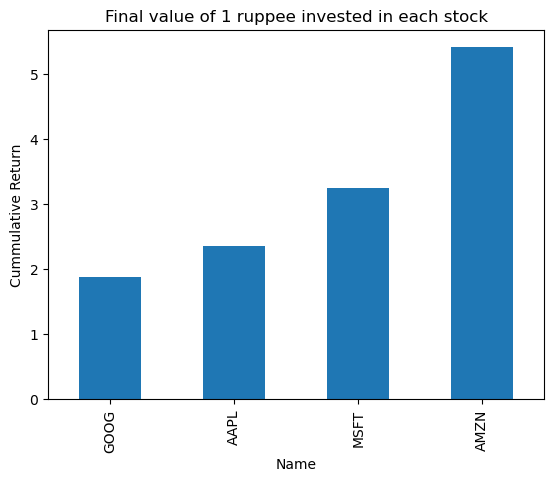

In [72]:
final_returns.sort_values().plot(kind="bar")
plt.title("Final value of 1 ruppee invested in each stock")
plt.ylabel("Cummulative Return")
plt.show

Rs.1 Lakh/Million SAFE INVESTMENT SIMULATION

In [73]:
best_stock = final_returns.idxmax()

In [74]:
best_stock

'AMZN'

In [78]:
investment=1000000

In [79]:
df_best=all_data[all_data["Name"]==best_stock]

In [80]:
df_best

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
1259,2013-02-08,261.40,265.25,260.555,261.95,3879078,AMZN,NaN,NaN
1260,2013-02-11,263.20,263.25,256.600,257.21,3403403,AMZN,-0.018095,0.981905
1261,2013-02-12,259.19,260.16,257.000,258.70,2938660,AMZN,0.005793,0.987593
1262,2013-02-13,261.53,269.96,260.300,269.47,5292996,AMZN,0.041631,1.028708
1263,2013-02-14,267.37,270.65,265.400,269.24,3462780,AMZN,-0.000854,1.027830
...,...,...,...,...,...,...,...,...,...
2513,2018-02-01,1445.00,1459.88,1385.140,1390.00,9113808,AMZN,-0.041967,5.306356
2514,2018-02-02,1477.39,1498.00,1414.000,1429.95,11125722,AMZN,0.028741,5.458866
2515,2018-02-05,1402.62,1458.98,1320.720,1390.00,11494985,AMZN,-0.027938,5.306356
2516,2018-02-06,1361.46,1443.99,1351.790,1442.84,11066819,AMZN,0.038014,5.508074


In [82]:
df_best["investment_value"]=df_best["cumulative_return"]*investment

In [83]:
df_best["investment_value"]

1259             NaN
1260    9.819049e+05
1261    9.875931e+05
1262    1.028708e+06
1263    1.027830e+06
            ...     
2513    5.306356e+06
2514    5.458866e+06
2515    5.306356e+06
2516    5.508074e+06
2517    5.408589e+06
Name: investment_value, Length: 1259, dtype: float64

In [84]:
df_best["investment_value"].tail(1).values[0]

np.float64(5408589.425462884)

In [85]:
df_best.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'Name',
       'daily_return', 'cumulative_return', 'investment_value'],
      dtype='object')

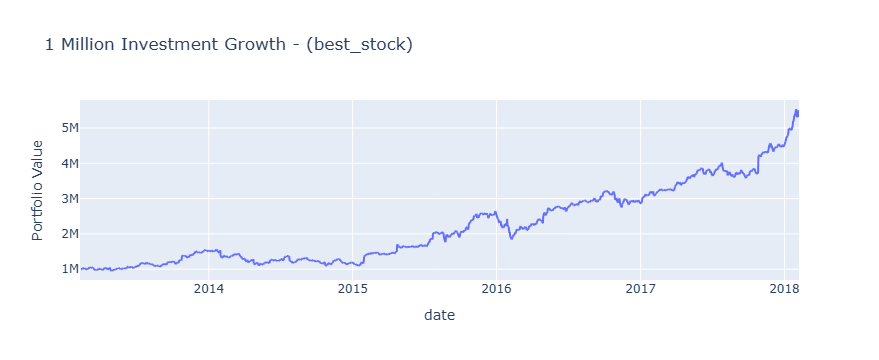

In [87]:
px.line(df_best,
        x = "date",
        y="investment_value" ,
        title= f"1 Million Investment Growth - (best_stock)",
        labels={
            'investment_value' : "Portfolio Value"
        })

Worst Market Crash Days (Top Losses)

In [91]:
all_data[all_data["Name"]=="AAPL"].nsmallest(5, 'daily_return')

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
243,2014-01-28,72.6799,73.5714,71.7242,72.3571,266833581,AAPL,-0.079927,1.066361
746,2016-01-27,96.0400,96.6289,93.3400,93.4200,133369674,AAPL,-0.065707,1.376775
809,2016-04-27,96.0000,98.7100,95.6800,97.8200,114602142,AAPL,-0.062578,1.441620
638,2015-08-21,110.4300,111.9000,105.6450,105.7600,128275471,AAPL,-0.061163,1.558636
46,2013-04-17,60.0385,60.0857,56.8728,57.5428,236138966,AAPL,-0.054993,0.848036


In [94]:
worst_days=all_data.groupby('Name',group_keys = False).apply(lambda x : x.nsmallest(5, 'daily_return'))

In [95]:
worst_days

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
243,2014-01-28,72.6799,73.5714,71.7242,72.3571,266833581,AAPL,-0.079927,1.066361
746,2016-01-27,96.0400,96.6289,93.3400,93.4200,133369674,AAPL,-0.065707,1.376775
809,2016-04-27,96.0000,98.7100,95.6800,97.8200,114602142,AAPL,-0.062578,1.441620
638,2015-08-21,110.4300,111.9000,105.6450,105.7600,128275471,AAPL,-0.061163,1.558636
46,2013-04-17,60.0385,60.0857,56.8728,57.5428,236138966,AAPL,-0.054993,0.848036
1505,2014-01-31,371.7600,375.4500,357.7600,358.6900,16181519,AMZN,-0.109972,1.369307
1563,2014-04-25,316.2500,316.4900,302.7100,303.8300,16186737,AMZN,-0.098828,1.159878
1626,2014-07-25,317.3000,324.8700,314.7600,324.0100,17855141,AMZN,-0.096484,1.236915
1690,2014-10-24,284.4000,293.8100,284.0000,287.0600,19805911,AMZN,-0.083403,1.095858
2007,2016-01-29,571.9800,593.0000,570.0000,587.0000,14677550,AMZN,-0.076100,2.240886


In [96]:
worst_days.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'Name',
       'daily_return', 'cumulative_return'],
      dtype='object')

In [97]:
worst_days[["Name","date","daily_return"]]

,Name,date,daily_return
243,AAPL,2014-01-28,-0.079927
746,AAPL,2016-01-27,-0.065707
809,AAPL,2016-04-27,-0.062578
638,AAPL,2015-08-21,-0.061163
46,AAPL,2013-04-17,-0.054993
1505,AMZN,2014-01-31,-0.109972
1563,AMZN,2014-04-25,-0.098828
1626,AMZN,2014-07-25,-0.096484
1690,AMZN,2014-10-24,-0.083403
2007,AMZN,2016-01-29,-0.076100


In [98]:
worst_days.dtypes

date                  object
open                 float64
high                 float64
low                  float64
close                float64
volume                 int64
Name                  object
daily_return         float64
cumulative_return    float64
dtype: object

In [100]:
worst_days["date"] = pd.to_datetime(worst_days["date"])

In [101]:
worst_days.dtypes

date                 datetime64[ns]
open                        float64
high                        float64
low                         float64
close                       float64
volume                        int64
Name                         object
daily_return                float64
cumulative_return           float64
dtype: object

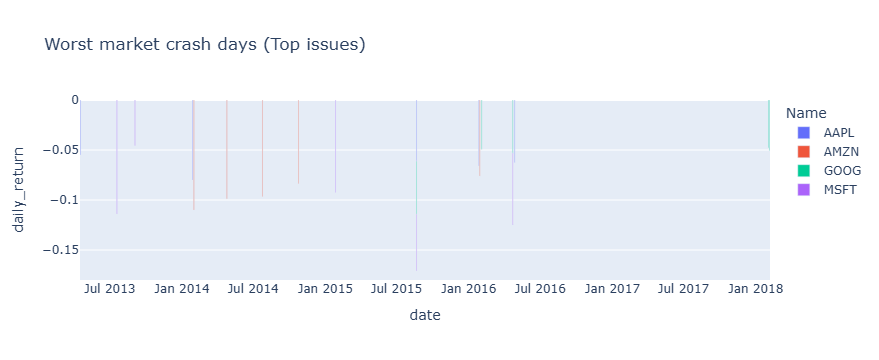

In [103]:
fig = px.bar(
    worst_days,
    x = 'date',
    y = 'daily_return',
    color = "Name",
    title = "Worst market crash days (Top issues)"
)
fig.show()

In [105]:
worst_days["crash_label"] = worst_days["Name"]+ " | " +worst_days["date"].dt.strftime("%Y:%m:%d")

In [106]:
worst_days

,date,open,high,low,close,volume,Name,daily_return,cumulative_return,crash_label
243,2014-01-28,72.6799,73.5714,71.7242,72.3571,266833581,AAPL,-0.079927,1.066361,AAPL | 2014:01:28
746,2016-01-27,96.0400,96.6289,93.3400,93.4200,133369674,AAPL,-0.065707,1.376775,AAPL | 2016:01:27
809,2016-04-27,96.0000,98.7100,95.6800,97.8200,114602142,AAPL,-0.062578,1.441620,AAPL | 2016:04:27
638,2015-08-21,110.4300,111.9000,105.6450,105.7600,128275471,AAPL,-0.061163,1.558636,AAPL | 2015:08:21
46,2013-04-17,60.0385,60.0857,56.8728,57.5428,236138966,AAPL,-0.054993,0.848036,AAPL | 2013:04:17
1505,2014-01-31,371.7600,375.4500,357.7600,358.6900,16181519,AMZN,-0.109972,1.369307,AMZN | 2014:01:31
1563,2014-04-25,316.2500,316.4900,302.7100,303.8300,16186737,AMZN,-0.098828,1.159878,AMZN | 2014:04:25
1626,2014-07-25,317.3000,324.8700,314.7600,324.0100,17855141,AMZN,-0.096484,1.236915,AMZN | 2014:07:25
1690,2014-10-24,284.4000,293.8100,284.0000,287.0600,19805911,AMZN,-0.083403,1.095858,AMZN | 2014:10:24
2007,2016-01-29,571.9800,593.0000,570.0000,587.0000,14677550,AMZN,-0.076100,2.240886,AMZN | 2016:01:29


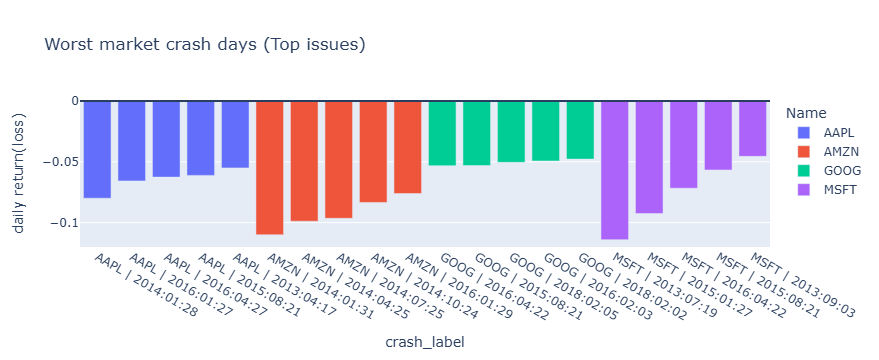

In [110]:
fig = px.bar(
    worst_days,
    x = "crash_label",
    y = "daily_return",
    color = "Name",
    title = "Worst market crash days (Top issues)",
    labels = {
        "daily_return" : "daily return(loss)"
    }
)
fig.add_hline(y=0)
fig.show()

Moving Average(Trend Analysis)

In [111]:
all_data['close']

0       67.8542
1       68.5614
2       66.8428
3       66.7156
4       66.6556
         ...   
4747    94.2600
4748    91.7800
4749    88.0000
4750    91.3300
4751    89.6100
Name: close, Length: 4752, dtype: float64

In [113]:
all_data["MA20"] = all_data.groupby('Name')['close'].transform(lambda x : x.rolling(20).mean())

In [114]:
all_data["MA50"] = all_data.groupby('Name')['close'].transform(lambda x : x.rolling(50).mean())

In [115]:
all_data.head(5)

,date,open,high,low,close,volume,Name,daily_return,cumulative_return,MA20,MA50
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL,NaN,NaN,NaN,NaN
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL,0.010422,1.010422,NaN,NaN
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL,-0.025067,0.985095,NaN,NaN
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL,-0.001903,0.983220,NaN,NaN
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL,-0.000899,0.982336,NaN,NaN


In [116]:
all_data.head(25)

,date,open,high,low,close,volume,Name,daily_return,cumulative_return,MA20,MA50
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL,NaN,NaN,NaN,NaN
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL,0.010422,1.010422,NaN,NaN
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL,-0.025067,0.985095,NaN,NaN
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL,-0.001903,0.983220,NaN,NaN
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL,-0.000899,0.982336,NaN,NaN
5,2013-02-15,66.9785,67.1656,65.7028,65.7371,97924631,AAPL,-0.013780,0.968799,NaN,NaN
6,2013-02-19,65.8714,66.1042,64.8356,65.7128,108854046,AAPL,-0.000370,0.968441,NaN,NaN
7,2013-02-20,65.3842,65.3842,64.1142,64.1214,118891367,AAPL,-0.024218,0.944988,NaN,NaN
8,2013-02-21,63.7142,64.1671,63.2599,63.7228,111596821,AAPL,-0.006216,0.939114,NaN,NaN
9,2013-02-22,64.1785,64.5142,63.7999,64.4014,82583823,AAPL,0.010649,0.949114,NaN,NaN


In [118]:
df_stock = all_data[all_data["Name"]=="AAPL"]

In [119]:
df_stock.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'Name',
       'daily_return', 'cumulative_return', 'MA20', 'MA50'],
      dtype='object')

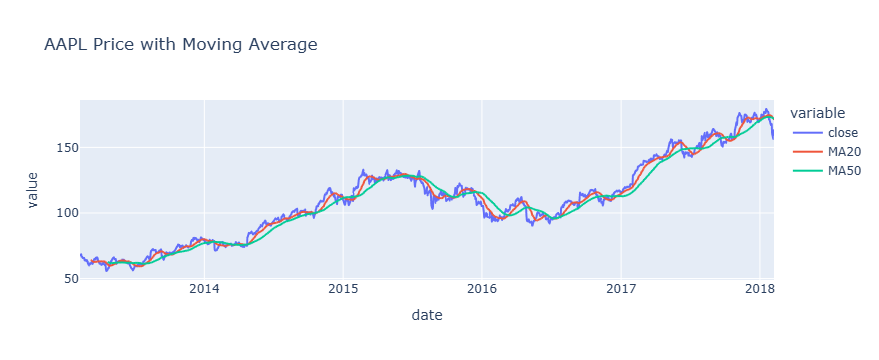

In [120]:
px.line(df_stock,
       x="date",
       y = ['close','MA20','MA50'],
        title = "AAPL Price with Moving Average"
            )

Best Month To Invest In Each Stock

In [127]:
all_data.dtypes

date                  object
open                 float64
high                 float64
low                  float64
close                float64
volume                 int64
Name                  object
daily_return         float64
cumulative_return    float64
MA20                 float64
MA50                 float64
dtype: object

In [128]:
all_data["date"] = pd.to_datetime(all_data["date"])

In [129]:
all_data.dtypes

date                 datetime64[ns]
open                        float64
high                        float64
low                         float64
close                       float64
volume                        int64
Name                         object
daily_return                float64
cumulative_return           float64
MA20                        float64
MA50                        float64
dtype: object

In [130]:
all_data['month_name'] = all_data["date"].dt.month_name()

In [131]:
monthly_returns = all_data.groupby(["Name","month_name"])["daily_return"].mean().reset_index()

In [132]:
monthly_returns

,Name,month_name,daily_return
0,AAPL,April,-0.000335
1,AAPL,August,0.001834
2,AAPL,December,-0.001343
3,AAPL,February,0.001532
4,AAPL,January,-0.000770
5,AAPL,July,0.002413
6,AAPL,June,-0.002175
7,AAPL,March,0.001537
8,AAPL,May,0.002444
9,AAPL,November,0.001438


In [133]:
monthly_returns.columns

Index(['Name', 'month_name', 'daily_return'], dtype='object')

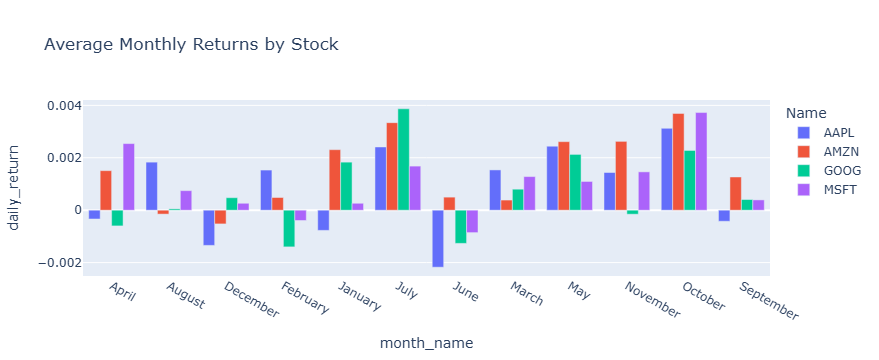

In [135]:
px.bar(monthly_returns,
       x =  "month_name",
       y = "daily_return",
       color = "Name",
       barmode = "group",
       title = "Average Monthly Returns by Stock")